# 2 · Your first classifier

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vitormeriat/text4gcn/blob/main/docs/tutorials/02_first_classifier.ipynb)

In tutorial 1 we built a graph of twelve sentences. Now we use the
**20 Newsgroups** benchmark (one of the datasets of Yao et al., 2019 and
Pereira & de Castro, DCAI 2022) and go all the way to test accuracy:

1. **Download** it and write the Text4GCN input files.
2. **Preprocess** it with `TextPipeline`.
3. **Build the graph** with `Frequency.tfidf()`.
4. **Train and evaluate** a GCN with `GNN.fit()`.

> **Runtime:** with the 4-category subset (~3.6k documents) this takes about 2 min on a Colab T4 GPU and about 6 min on CPU. It needs about 4 GB of RAM.

| # | Tutorial | Question it answers |
|---|---|---|
| 1 | Text as a graph | What does the graph look like, and why does it help? |
| 2 | **Your first classifier** | How do I go from raw text to test accuracy? |
| 3 | Choosing a graph builder | How should words be connected? |
| 4 | Refining the graph | Can a smaller graph do as well? |
| 5 | Bring your own corpus | How do I use my own (non-English) data? |

In [1]:
%pip install -q text4gcn
# Release candidate from TestPyPI (dependencies still come from PyPI):
# %pip install -q -i https://test.pypi.org/simple/ --extra-index-url https://pypi.org/simple/ "text4gcn==2.0.0rc2"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import shutil
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

import text4gcn
from text4gcn import GNN, Builder, TextPipeline
from text4gcn.builder import Frequency
from text4gcn.datasets import twenty_newsgroups

print(f"text4gcn {text4gcn.__version__}")

text4gcn 2.0.0rc2


## Configuration

The whole corpus, documents **and** vocabulary, becomes a single graph. The
full 20NG (18,846 posts) therefore needs a large GPU. We use the four
categories of the classic scikit-learn text tutorial. To scale up, add
categories or set `CATEGORIES = None`.

In [3]:
NAME = "20NG4"
DATA_DIR = Path("data")
LOG_DIR = Path("logs")
SEED = 1234
CATEGORIES = ["alt.atheism", "soc.religion.christian", "comp.graphics", "sci.med"]

## 1. Download and write the input files

`twenty_newsgroups()` downloads the corpus with scikit-learn (already a
dependency) and keeps the official train/test split. It strips e-mail headers,
signatures and quoted replies, so the model learns from the message body, and
it drops posts left with fewer than 5 words. It then calls `save_corpus()`,
which writes the two files every Text4GCN dataset needs:

| File | One line per document |
|---|---|
| `<name>.txt` | the text, on a single line |
| `<name>.meta` | `<doc id>\t<train|test>\t<label>` |

`TextPipeline` never overwrites its outputs, so we start from an empty folder.

In [4]:
shutil.rmtree(DATA_DIR, ignore_errors=True)
txt_path, meta_path = twenty_newsgroups(DATA_DIR, name=NAME, categories=CATEGORIES)

meta = pd.read_csv(meta_path, sep="\t", names=["id", "split", "label"])
meta.pivot_table(index="label", columns="split", values="id", aggfunc="count", margins=True)

split,test,train,All
label,,,
alt.atheism,309,464,773
comp.graphics,383,564,947
sci.med,379,575,954
soc.religion.christian,384,589,973
All,1455,2192,3647


In [5]:
print(txt_path.read_text(encoding="utf-8").splitlines()[0][:400])

Does anyone know of a good way (standard PC application/PD utility) to convert tif/img/tga files into LaserJet III format. We would also like to do the same, converting to HPGL (HP plotter) files. Please email any response. Is this the correct group? Thanks in advance. Michael.


## 2. Preprocess

`execute()` writes three folders next to the input files:

| Folder | Content |
|---|---|
| `<name>.cleaned/` | text lower-cased and tokenized, without stop words and words seen fewer than `rare_count` times |
| `<name>.shuffled/` | documents shuffled with `seed`, the vocabulary, the train/test ids |
| `<name>.node_features/` | feature and label matrices; `validation_ratio` of the training documents is held out for validation |

`validation_ratio` is the **only** place where the validation split is defined.

In [6]:
TextPipeline(
    dataset_name=NAME,
    dataset_path=DATA_DIR,
    rare_count=5,
    language="english",
    seed=SEED,
).execute(validation_ratio=0.10)

[2026/10/16 14:10:21] [INFO] ======================================== NLTK Configuration ========================================


[nltk_data] Downloading package stopwords to /home/vitor/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/vitor/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/vitor/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


[2026/10/16 14:10:21] [INFO] Random seed (shuffle) = <1234>
[2026/10/16 14:10:21] [INFO] Validation ratio = <0.1>
[2026/10/16 14:10:21] [INFO] 
[2026/10/16 14:10:21] [INFO] ============================= CLEANED DATA: Removed rare & stop-words. =============================
[2026/10/16 14:10:21] [INFO] Start process: 1792156221.8414643
[2026/10/16 14:10:22] [INFO] Rare-Count = <5>
[2026/10/16 14:10:22] [INFO] Elapsed time is 1.102897 seconds.
[2026/10/16 14:10:22] [INFO] 
[2026/10/16 14:10:22] [INFO] ============================ SHUFFLED DATA: Corpus documents shuffled. =============================
[2026/10/16 14:10:22] [INFO] Start process: 1792156222.9445217
[2026/10/16 14:10:23] [INFO] Elapsed time is 0.153735 seconds.
[2026/10/16 14:10:23] [INFO] 
[2026/10/16 14:10:23] [INFO] ======================= PREPARED WORDS: Vocabulary & word-vectors extracted. =======================
[2026/10/16 14:10:23] [INFO] Start process: 1792156223.098409
[2026/10/16 14:10:28] [INFO] Elapsed time is 5

/home/vitor/repos/Text4GNNs/text4gcn/text4gcn/modules/node_features.py:76: RuntimeWarning: invalid value encountered in divide
  mean_doc_vec = (doc_vec / len(words)).tolist()


[2026/10/16 14:10:31] [INFO] x.shape=(1973, 300), y.shape=(1973, 4)
[2026/10/16 14:10:31] [INFO] tx.shape=(1455, 300), ty.shape=(1455, 4)
[2026/10/16 14:10:31] [INFO] allx.shape=(13082, 300), ally.shape=(13082, 4)
[2026/10/16 14:10:31] [INFO] Elapsed time is 2.335325 seconds.
[2026/10/16 14:10:31] [INFO] 


In [7]:
vocab = (DATA_DIR / f"{NAME}.shuffled" / f"{NAME}.vocab").read_text(encoding="utf-8").split()
print(f"vocabulary: {len(vocab):,} words -> graph with {len(meta) + len(vocab):,} nodes")

vocabulary: 10,890 words -> graph with 14,537 nodes


## 3. Build the graph

The TextGCN graph has PMI word–word edges and TF-IDF document–word edges (see
tutorial 1). `GraphBuildStats` reports its size.

In [8]:
stats = Frequency(dataset_name=NAME, dataset_path=DATA_DIR).tfidf(window_size=20)
stats

[2026/10/16 14:10:31] [INFO] =============== EXTRACTED ADJACENCY MATRIX: Heterogenous doc-word adjacency matrix. ================
[2026/10/16 14:10:31] [INFO] Start process: 1792156231.303183
[2026/10/16 14:10:32] [INFO] Calculating PMI
[2026/10/16 14:14:20] [INFO] Calculating TF-IDF
[2026/10/16 14:14:22] [INFO] [INFO] (4534779, (4534779, 4534779)), shape=(14537, 14537)
[2026/10/16 14:14:24] [INFO] GraphBuildStats(frequency.tfidf: nodes=14537, edges(nnz)=4534779, density=2.145886e-02, file=51.95 MiB)
[2026/10/16 14:14:24] [INFO] Elapsed time is 233.623438 seconds.
[2026/10/16 14:14:24] [INFO] 
[2026/10/16 14:14:24] [WARN] Directory:'data/log' already exists, not overwritten.


GraphBuildStats(n_nodes=14537, n_edges=4534779, density=0.02145885503625945, file_bytes=54475923, builder='frequency.tfidf', dataset_name='20NG4', path='data/20NG4.adjacency/ind.frequency.tfidf.20NG4.adj')

## 4. Train and evaluate

`GNN` loads the features and the graph and trains a 2-layer GCN with the
protocol of the paper: hidden size 200, dropout 0.5, learning rate 0.02, and
early stopping after 10 epochs without improvement. It uses CUDA when available. When training
stops, the weights with the best validation loss are restored and evaluated on
the test documents.

In [9]:
result = GNN(
    dataset_name=NAME,
    dataset_path=DATA_DIR,
    log_dir=LOG_DIR,
    builder=Builder.Tfidf,      # the graph built in step 3
    seed=SEED,
).fit()

Using device: cpu

============================== MODEL CONFIGURATION
Namespace(early_stopping=10, seed=1234, val_ratio=0.1, max_epoch=200, dataset='20NG4', dropout=0.5, log_dir=PosixPath('logs'), layer=<Layer.GCN: 'GCN'>, nhid=200, lr=0.02, device=device(type='cpu'))


Show info about load data:

Data      Shape
--------  --------------
x         (1973, 300)
y         (1973, 4)
tx        (1455, 300)
ty        (1455, 4)
allx      (13082, 300)
ally      (13082, 4)
adj       (14537, 14537)
Features  (14537, 300)
Labels    (14537, 4)

Data statistics

  Edges    Classes    Train samples    Val samples    Test samples
-------  ---------  ---------------  -------------  --------------
  14537          4             1973            219            1455

Model structure:

 GCN(
  (layer1): GraphConvolution(
    (act_func): ReLU()
    (dropout): Dropout(p=0.5, inplace=False)
  )
  (layer2): GraphConvolution(
    (dropout): Dropout(p=0.5, inplace=False)
  )
) 

Dropout rate: 0.5
Layer: layer1.W0

In [10]:
print(f"test accuracy : {result.test_accuracy:.4f}")
print(f"epochs trained: {result.epochs_trained}")
print(f"checkpoint    : {result.model_path}")

test accuracy : 0.8674
epochs trained: 52
checkpoint    : logs/20261016-132106470.pth


Training curves are saved in `log_dir`.

The loss values stay close to $\ln(4) \approx 1.39$, and the validation curve looks
almost flat. This is expected: as in the reference TextGCN implementation, the
cross-entropy is averaged over **all** nodes, and the rows outside each split
have zeroed logits. Accuracy is the curve to read.

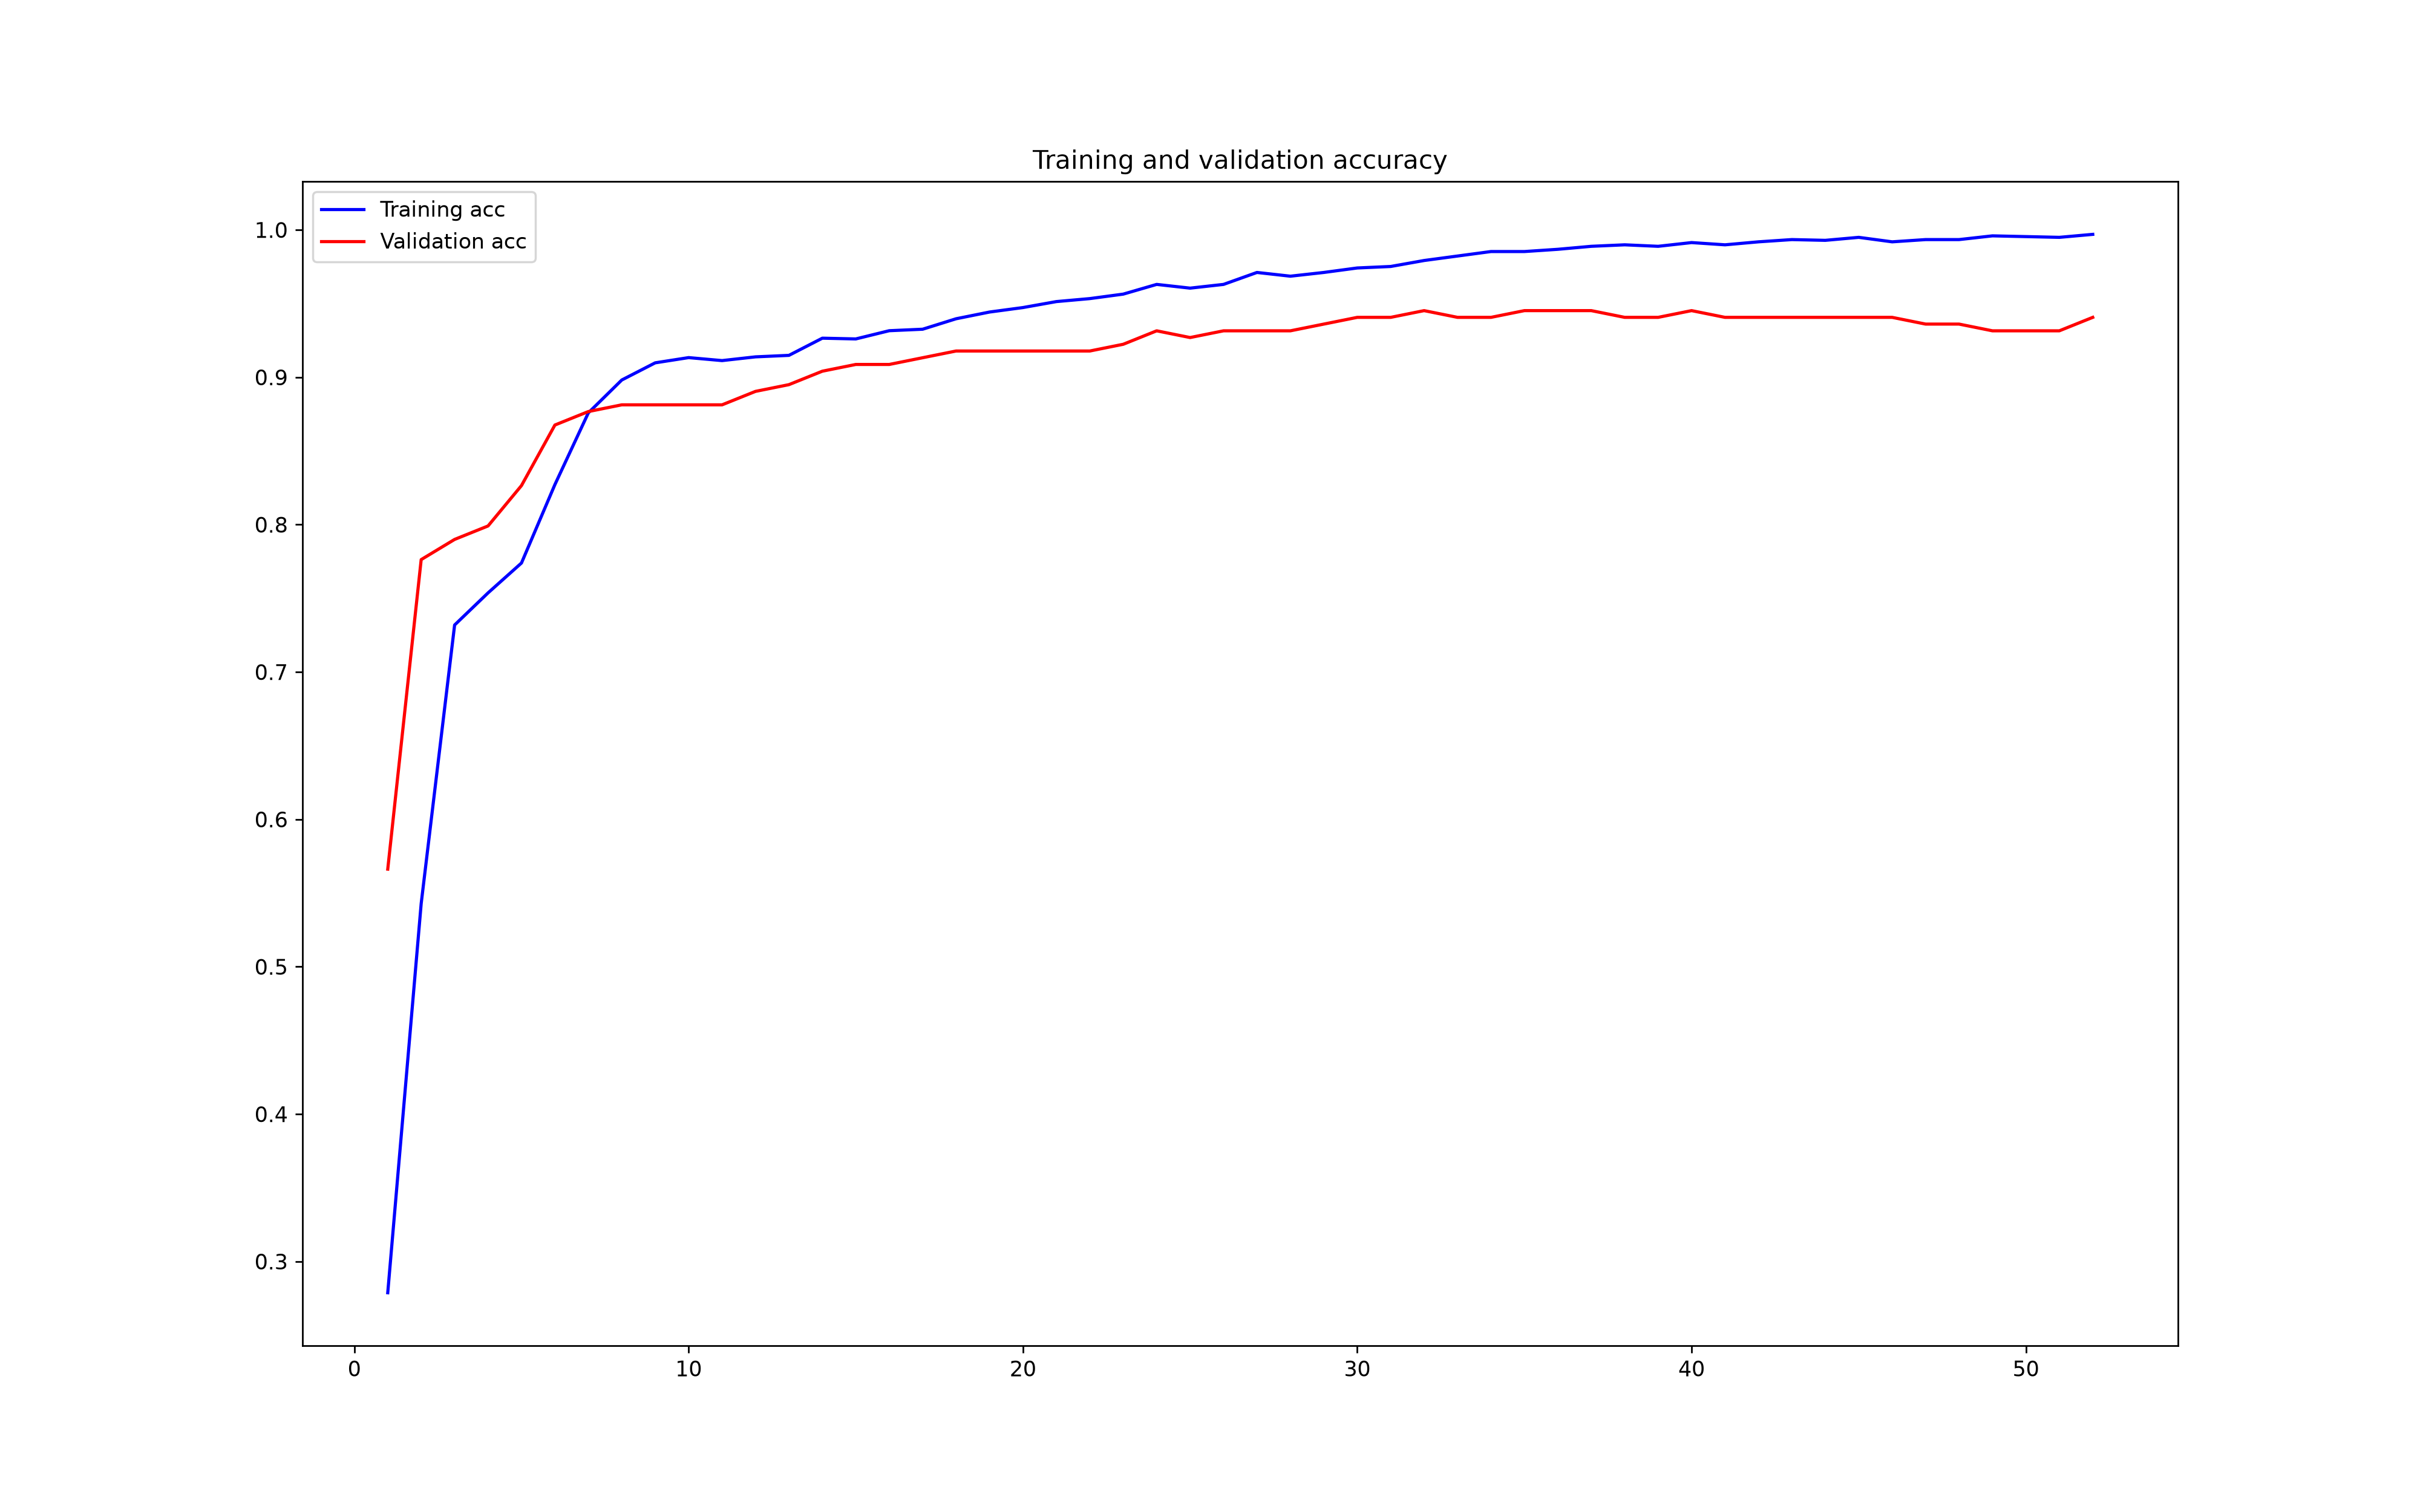

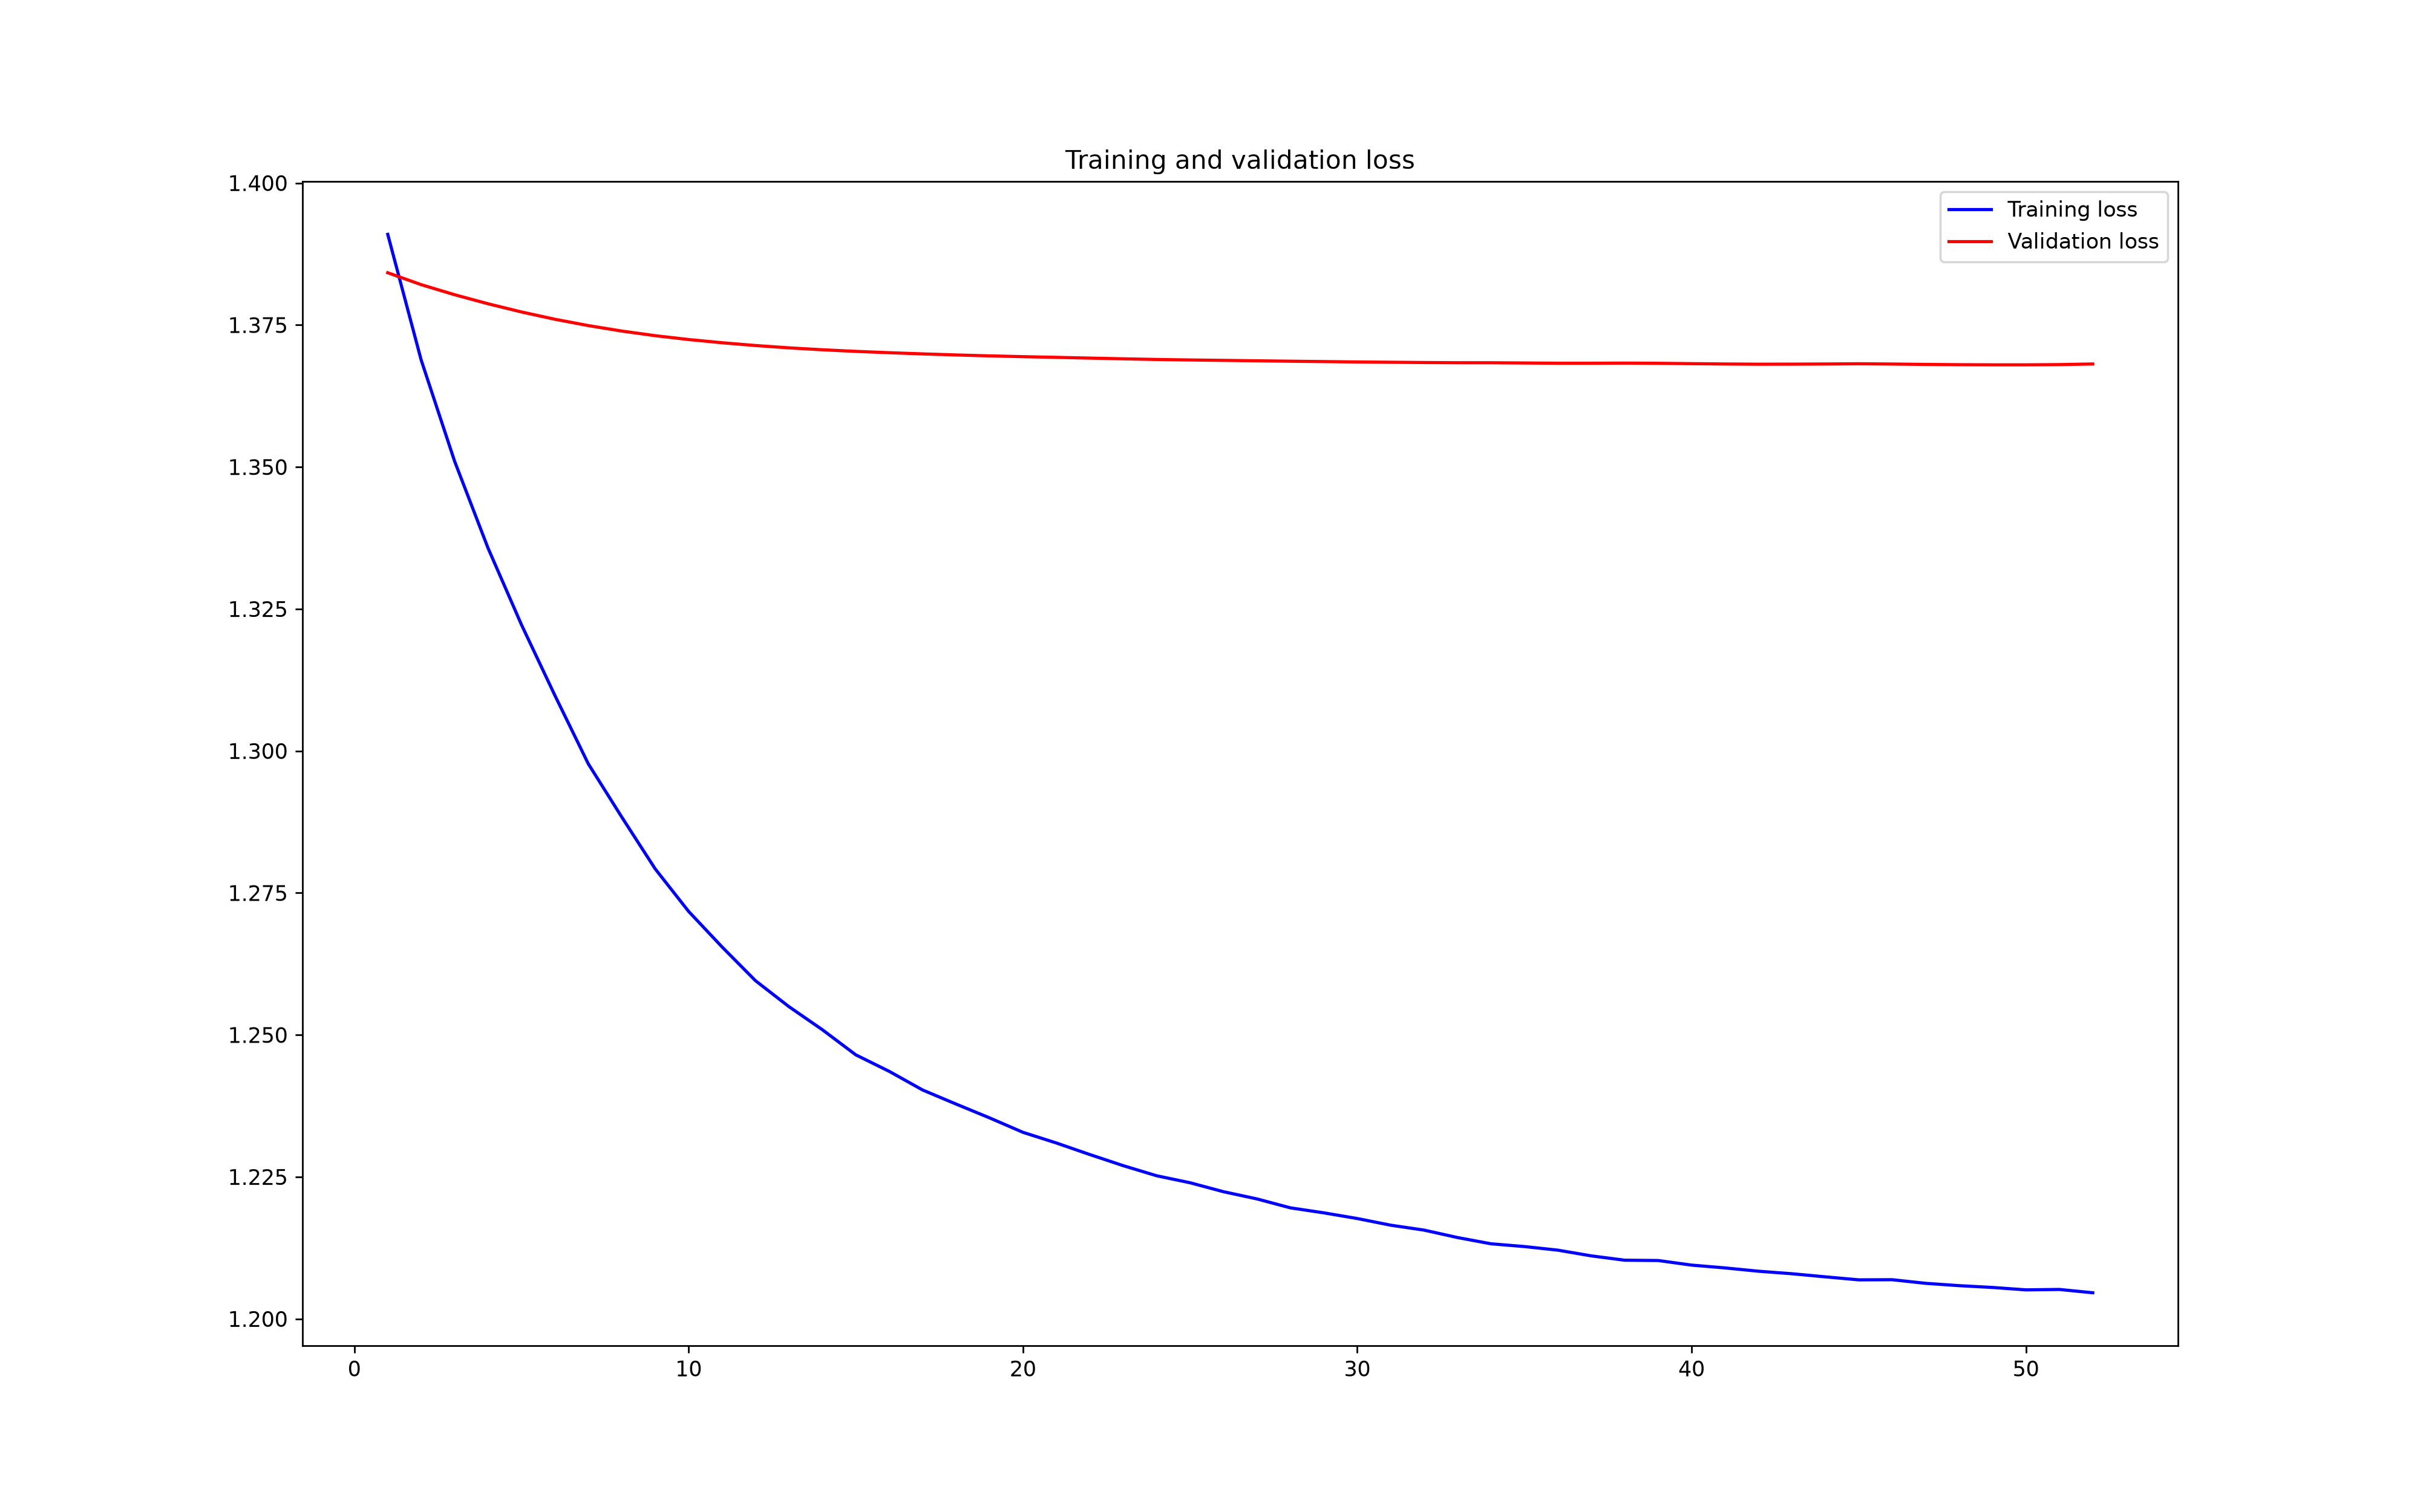

In [11]:
display(Image(LOG_DIR / "metrics-acc.png"), Image(LOG_DIR / "metrics-loss.png"))

## What's next

The graph above has millions of edges, most of them word–word PMI pairs. Do we
need all of them?

**Next:** [3 · Choosing a graph builder](https://vitormeriat.github.io/text4gcn/tutorials/03_choosing_a_graph_builder/) builds the graph in other
ways and compares size, speed and accuracy.